# 01. Exploração dos dados: evasão no ensino superior

**Projeto N3 · Turma 8NA · Equipe 10**

Neste notebook conhecemos o dataset, procuramos padrões ligados à evasão e justificamos os tratamentos aplicados antes da modelagem (notebook `02_modelagem_avaliacao.ipynb`).

**Fonte dos dados:** *Predict Students' Dropout and Academic Success*, UCI Machine Learning Repository (Realinho et al., 2021, licença CC BY 4.0). São 4.424 alunos de 17 cursos de graduação do Instituto Politécnico de Portalegre (Portugal), que ingressaram entre 2008/09 e 2018/19. Para cada aluno há dados conhecidos na matrícula (perfil, família, forma de ingresso, situação financeira), o desempenho nos dois primeiros semestres e indicadores macroeconômicos do ano de ingresso. O alvo é a situação do aluno ao fim do tempo normal do curso: **evadiu**, **ainda matriculado** ou **formado**.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

CORES = {"Evadiu": "#d1495b", "Matriculado": "#edae49", "Formado": "#00798c"}
ORDEM = ["Evadiu", "Matriculado", "Formado"]
PASTA_FIGURAS = RAIZ / "reports" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)


def salvar(fig, nome):
    fig.savefig(PASTA_FIGURAS / nome, dpi=120, bbox_inches="tight")

from src.dados import BINARIAS, CATEGORICAS, carregar_dados, carregar_dados_brutos

## 1. Visão geral

As colunas foram renomeadas para português (`src/dados.py`). O cabeçalho original tem um caractere TAB escondido em `Daytime/evening attendance`, que é removido na leitura.

In [2]:
bruto = carregar_dados_brutos()
df = carregar_dados()
print(f"{len(df)} alunos | {bruto.shape[1] - 1} atributos + 1 alvo")
print(f"Valores ausentes: {bruto.isna().sum().sum()} | linhas duplicadas: {bruto.duplicated().sum()}")
df.head()

4424 alunos | 36 atributos + 1 alvo
Valores ausentes: 0 | linhas duplicadas: 0


,estado_civil,forma_ingresso,ordem_opcao,curso,turno_diurno,escolaridade_anterior,nota_escolaridade_anterior,nacionalidade,escolaridade_mae,escolaridade_pai,ocupacao_mae,ocupacao_pai,nota_admissao,deslocado,necessidades_especiais,devedor,mensalidades_em_dia,sexo_masculino,bolsista,idade_ingresso,internacional,disc_1sem_creditadas,disc_1sem_matriculadas,disc_1sem_avaliacoes,disc_1sem_aprovadas,disc_1sem_nota_media,disc_1sem_sem_avaliacao,disc_2sem_creditadas,disc_2sem_matriculadas,disc_2sem_avaliacoes,disc_2sem_aprovadas,disc_2sem_nota_media,disc_2sem_sem_avaliacao,taxa_desemprego,taxa_inflacao,pib,situacao,evadiu,nome_curso,taxa_aprovacao_1sem,taxa_aprovacao_2sem
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.8,1.4,1.74,Evadiu,1,Design de Animação e Multimídia,0.000,0.000
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.9,-0.3,0.79,Formado,0,Turismo,1.000,1.000
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.8,1.4,1.74,Evadiu,1,Design de Comunicação,0.000,0.000
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.4,-0.8,-3.12,Formado,0,Jornalismo e Comunicação,1.000,0.833
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.9,-0.3,0.79,Formado,0,Serviço Social (noturno),0.833,1.000


Não há valores ausentes nem linhas duplicadas, então **não é preciso imputar nem remover registros**. Os atributos se dividem em quatro grupos:

| Grupo | Exemplos | Como tratamos |
|---|---|---|
| Códigos nominais (9) | curso, forma de ingresso, estado civil, escolaridade e ocupação dos pais, nacionalidade | One-hot. O código é só um rótulo: o curso 9500 não é "maior" que o 171 |
| Binários (8) | mensalidades em dia, devedor, bolsista, sexo, turno, deslocado | Mantidos como 0/1 |
| Numéricos de matrícula (7) | nota de admissão, idade, ordem de opção, desemprego, inflação, PIB | Padronizados só na Regressão Logística |
| Desempenho por semestre (6 + 6) | disciplinas matriculadas, avaliadas, aprovadas, nota média | Mantidos, mais a **taxa de aprovação** criada por nós |

## 2. A variável-alvo

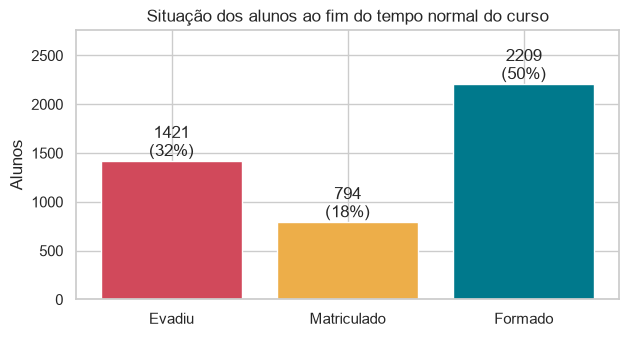

In [3]:
contagem = df["situacao"].value_counts().reindex(ORDEM)
fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(contagem.index, contagem.values, color=[CORES[s] for s in ORDEM])
for barra, valor in zip(barras, contagem.values):
    ax.annotate(f"{valor}\n({valor / len(df):.0%})", (barra.get_x() + barra.get_width() / 2, valor),
                ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.25)
ax.set_ylabel("Alunos")
ax.set_title("Situação dos alunos ao fim do tempo normal do curso")
salvar(fig, "01_situacao.png")
plt.show()

**32% dos alunos evadiram**, 18% ainda estavam matriculados (atrasados) e 50% se formaram.

**Decisão de modelagem:** o problema foi tratado como **classificação binária**, *evadiu* contra *não evadiu* (formado ou matriculado). O motivo é que a decisão da coordenação é binária: chamar ou não o aluno para acompanhamento. Um aluno atrasado mas ainda matriculado não abandonou o curso. No notebook 02 testamos também a versão com 3 classes e mostramos por que ela é pior para este uso.

As classes ficam moderadamente desbalanceadas (32% contra 68%). Por isso a validação é **estratificada** e a principal métrica é a **PR-AUC**, que olha diretamente para a classe "evadiu".

## 3. Evasão por curso

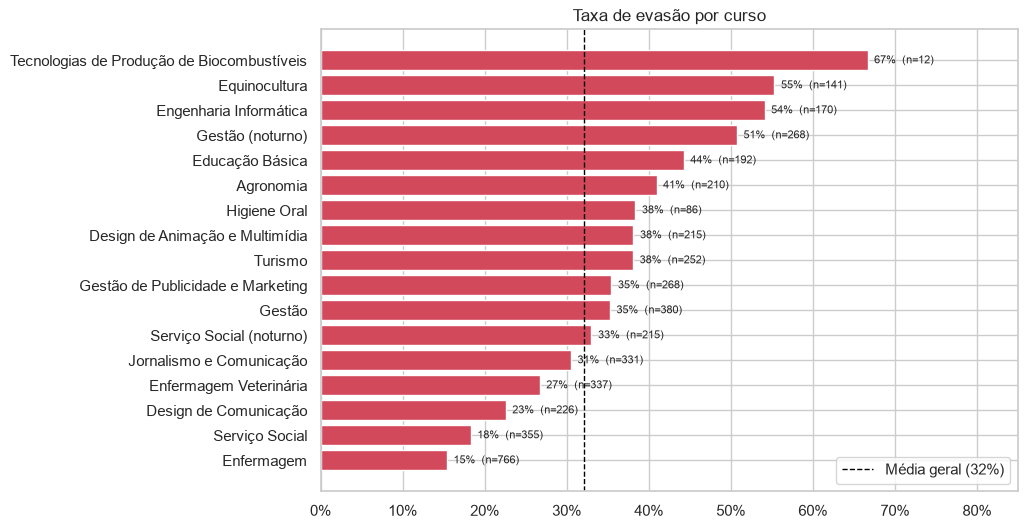

In [4]:
por_curso = (df.groupby("nome_curso")
               .agg(taxa_evasao=("evadiu", "mean"), alunos=("evadiu", "size"))
               .sort_values("taxa_evasao"))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(por_curso.index, por_curso["taxa_evasao"], color=CORES["Evadiu"])
media = df["evadiu"].mean()
ax.axvline(media, color="black", linestyle="--", linewidth=1, label=f"Média geral ({media:.0%})")
for i, (taxa, n) in enumerate(zip(por_curso["taxa_evasao"], por_curso["alunos"])):
    ax.text(taxa + 0.008, i, f"{taxa:.0%}  (n={n})", va="center", fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 0.85)
ax.set_title("Taxa de evasão por curso")
ax.legend(loc="lower right")
salvar(fig, "02_evasao_por_curso.png")
plt.show()

A evasão varia muito entre cursos: de **15% em Enfermagem** a **54% em Engenharia Informática** e **55% em Equinocultura**. O curso de Biocombustíveis tem só 12 alunos, então a taxa de 67% é pouco confiável. Os cursos noturnos (Gestão noturno: 51%) evadem mais que os diurnos equivalentes (Gestão: 35%). O curso entra no modelo como variável one-hot.

## 4. Fatores financeiros e de perfil

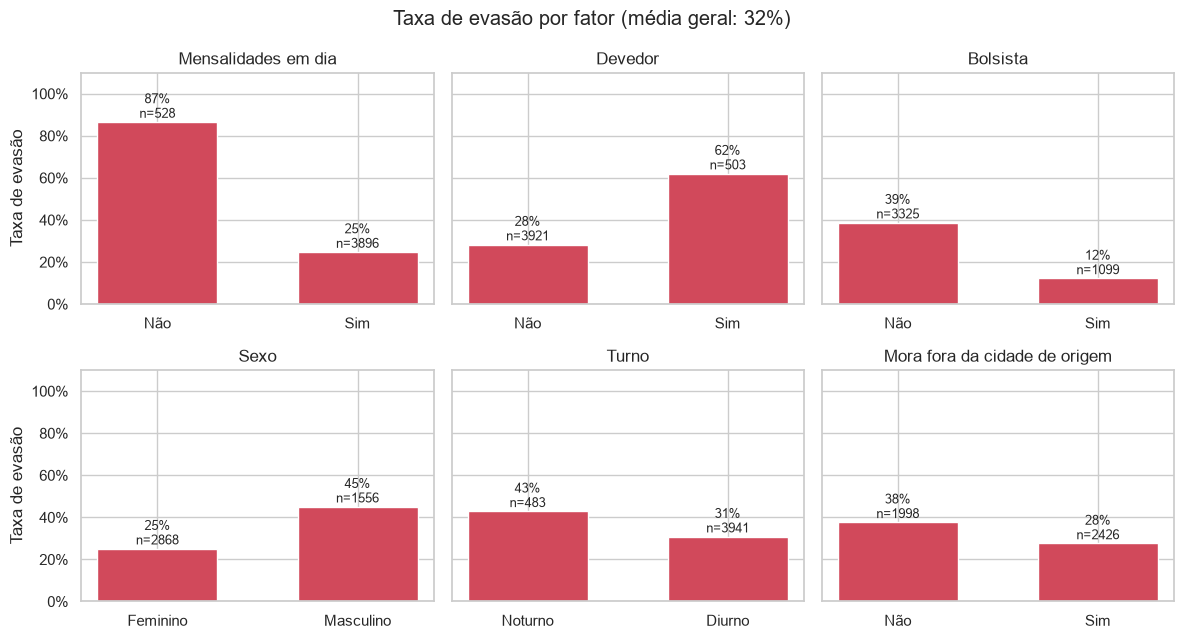

In [5]:
FATORES = {
    "mensalidades_em_dia": ("Mensalidades em dia", {0: "Não", 1: "Sim"}),
    "devedor": ("Devedor", {0: "Não", 1: "Sim"}),
    "bolsista": ("Bolsista", {0: "Não", 1: "Sim"}),
    "sexo_masculino": ("Sexo", {0: "Feminino", 1: "Masculino"}),
    "turno_diurno": ("Turno", {0: "Noturno", 1: "Diurno"}),
    "deslocado": ("Mora fora da cidade de origem", {0: "Não", 1: "Sim"}),
}
fig, eixos = plt.subplots(2, 3, figsize=(12, 6.5), sharey=True)
for ax, (coluna, (titulo, rotulos)) in zip(eixos.flat, FATORES.items()):
    resumo = df.groupby(coluna)["evadiu"].agg(["mean", "size"])
    ax.bar([rotulos[i] for i in resumo.index], resumo["mean"], color=CORES["Evadiu"], width=0.6)
    for i, (taxa, n) in enumerate(zip(resumo["mean"], resumo["size"])):
        ax.text(i, taxa + 0.02, f"{taxa:.0%}\nn={n}", ha="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
for ax in eixos[:, 0]:
    ax.set_ylabel("Taxa de evasão")
fig.suptitle("Taxa de evasão por fator (média geral: 32%)")
fig.tight_layout()
salvar(fig, "03_fatores_binarios.png")
plt.show()

- **Mensalidades atrasadas:** 87% evadiram, contra 25% de quem estava em dia. É o fator isolado mais forte entre os dados de matrícula.
- **Devedor:** 62% contra 28%.
- **Bolsistas** evadem bem menos: 12% contra 39%.
- Homens (45%) evadem mais que mulheres (25%), e o noturno (43%) mais que o diurno (31%).

⚠️ **Atenção:** o dataset não informa *quando* "mensalidades em dia" foi medido. Se for no fim do período, parte do atraso pode ser consequência da evasão, e não causa. No notebook 02 medimos quanto o modelo depende desse atributo.

## 5. Idade e nota de admissão

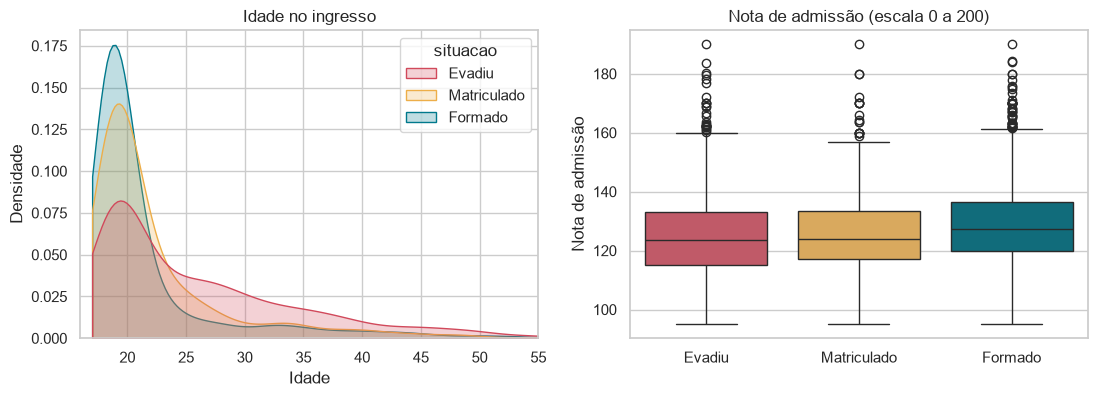

,idade_ingresso,nota_admissao
situacao,,
Evadiu,23.0,123.6
Matriculado,20.0,124.1
Formado,19.0,127.4


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x="idade_ingresso", hue="situacao", hue_order=ORDEM, palette=CORES,
            common_norm=False, fill=True, alpha=0.25, clip=(17, 70), ax=ax1)
ax1.set_xlim(16, 55)
ax1.set_title("Idade no ingresso")
ax1.set_xlabel("Idade")
ax1.set_ylabel("Densidade")
sns.boxplot(data=df, x="situacao", y="nota_admissao", order=ORDEM, hue="situacao",
            palette=CORES, legend=False, ax=ax2)
ax2.set_title("Nota de admissão (escala 0 a 200)")
ax2.set_xlabel("")
ax2.set_ylabel("Nota de admissão")
salvar(fig, "04_idade_nota_admissao.png")
plt.show()
df.groupby("situacao")[["idade_ingresso", "nota_admissao"]].median().reindex(ORDEM)

Quem evade entra mais velho: a mediana é **23 anos**, contra 19 dos formados. A cauda vai até 70 anos. Isso tem relação com a forma de ingresso "maiores de 23 anos" e com quem já trabalha e estuda à noite. A **nota de admissão** diferencia pouco: a mediana é 123,6 entre quem evadiu e 127,4 entre os formados.

**Valores extremos:** idades altas são plausíveis e foram **mantidas**. Não removemos *outliers*, porque nenhum valor é impossível e os modelos de árvore são robustos a eles.

## 6. Desempenho no 1º semestre

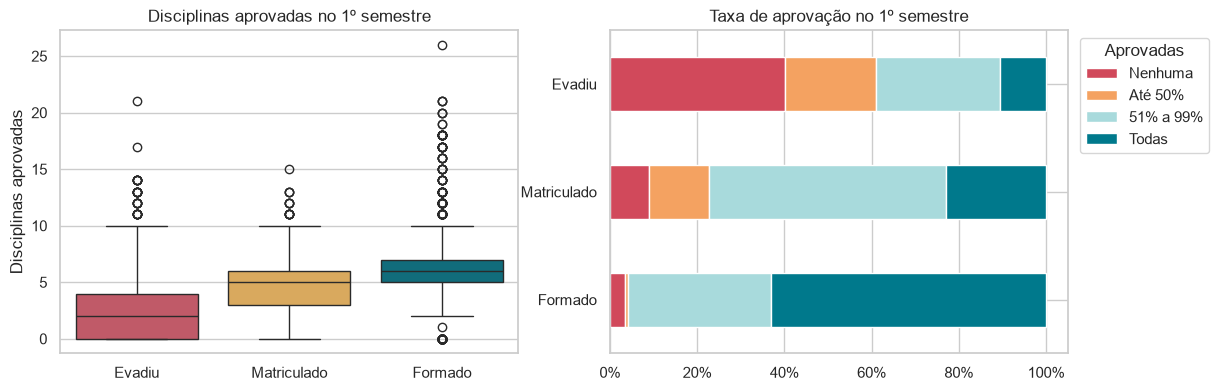

taxa_aprovacao_1sem,Nenhuma,Até 50%,51% a 99%,Todas
situacao,,,,
Formado,0.035,0.007,0.327,0.632
Matriculado,0.089,0.139,0.543,0.229
Evadiu,0.401,0.210,0.283,0.106


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=df, x="situacao", y="disc_1sem_aprovadas", order=ORDEM, hue="situacao",
            palette=CORES, legend=False, ax=ax1)
ax1.set_title("Disciplinas aprovadas no 1º semestre")
ax1.set_xlabel("")
ax1.set_ylabel("Disciplinas aprovadas")

faixas = pd.cut(df["taxa_aprovacao_1sem"], bins=[-0.01, 0, 0.5, 0.99, 1.0],
                labels=["Nenhuma", "Até 50%", "51% a 99%", "Todas"])
tabela = pd.crosstab(df["situacao"], faixas, normalize="index").reindex(ORDEM[::-1])
tabela.plot(kind="barh", stacked=True, ax=ax2, color=["#d1495b", "#f4a261", "#a8dadc", "#00798c"])
ax2.xaxis.set_major_formatter(PercentFormatter(1))
ax2.set_title("Taxa de aprovação no 1º semestre")
ax2.set_ylabel("")
ax2.legend(title="Aprovadas", bbox_to_anchor=(1.01, 1), loc="upper left")
salvar(fig, "05_desempenho_1sem.png")
plt.show()
tabela.round(3)

Este é o sinal mais forte do dataset: **40% de quem evadiu não foi aprovado em nenhuma disciplina no 1º semestre**, contra 3,5% dos formados. A taxa de aprovação mediana é 33% entre quem evadiu e 100% entre os formados.

Por isso criamos o atributo **`taxa_aprovacao_1sem` = aprovadas ÷ matriculadas**. Ele normaliza o desempenho pela carga de cada aluno (alunos com 0 disciplinas matriculadas recebem taxa 0). Também por isso a previsão melhora muito depois do 1º semestre, como mostra o notebook 02.

**Nota média 0** aparece em quem não fez avaliação. Isso **não é erro de digitação**, é informação real ("não fez provas"), e foi mantido.

## 7. Evasão por forma de ingresso

A forma de ingresso diz **por qual porta o aluno entrou** no curso. Em Portugal, a maioria entra pelo concurso nacional, dividido em **1ª, 2ª e 3ª fases** (parecido com as chamadas do SISU). Os demais entram por concursos especiais, como **maiores de 23 anos** e **titulares de outro curso superior** (o "portador de diploma" no Brasil), ou por **mudança de curso e transferência**.

São 18 códigos, e 6 deles têm menos de 20 alunos. Para não tirar conclusões de grupos minúsculos, eles foram juntados em "Outras", a mesma regra (`min_frequency=20`) que o one-hot do modelo usa. As barras de erro mostram o **intervalo de confiança de 95%** (Wilson) de cada taxa: quanto menor o grupo, maior a incerteza.

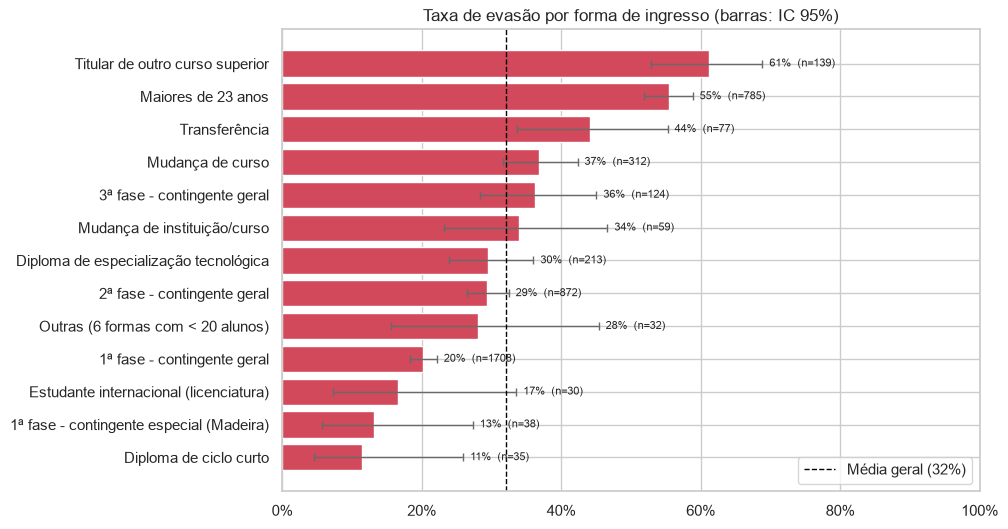

In [8]:
from src.dados import FORMAS_INGRESSO


def intervalo_wilson(evasoes, n, z=1.96):
    """Intervalo de confiança de 95% (Wilson) para uma proporção. Funciona bem mesmo com n pequeno."""
    p = evasoes / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margem, centro + margem


alunos_por_forma = df["forma_ingresso"].map(df["forma_ingresso"].value_counts())
formas_raras = (df["forma_ingresso"].value_counts() < 20).sum()
df["nome_forma_ingresso"] = np.where(alunos_por_forma >= 20, df["forma_ingresso"].map(FORMAS_INGRESSO),
                                     f"Outras ({formas_raras} formas com < 20 alunos)")

por_forma = (df.groupby("nome_forma_ingresso")
               .agg(alunos=("evadiu", "size"), evasoes=("evadiu", "sum"), taxa_evasao=("evadiu", "mean"))
               .sort_values("taxa_evasao"))
por_forma["ic_inferior"], por_forma["ic_superior"] = intervalo_wilson(por_forma["evasoes"], por_forma["alunos"])

fig, ax = plt.subplots(figsize=(9, 6))
erros = [por_forma["taxa_evasao"] - por_forma["ic_inferior"], por_forma["ic_superior"] - por_forma["taxa_evasao"]]
ax.barh(por_forma.index, por_forma["taxa_evasao"], xerr=erros, color=CORES["Evadiu"],
        error_kw={"ecolor": "dimgray", "elinewidth": 1, "capsize": 3})
media = df["evadiu"].mean()
ax.axvline(media, color="black", linestyle="--", linewidth=1, label=f"Média geral ({media:.0%})")
for i, (taxa, limite, n) in enumerate(zip(por_forma["taxa_evasao"], por_forma["ic_superior"], por_forma["alunos"])):
    ax.text(limite + 0.01, i, f"{taxa:.0%}  (n={n})", va="center", fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_title("Taxa de evasão por forma de ingresso (barras: IC 95%)")
ax.legend(loc="lower right")
salvar(fig, "13_evasao_forma_ingresso.png")
plt.show()

In [9]:
# Perfil de cada forma de ingresso: ajuda a entender por que algumas evadem mais
perfil = (df.groupby("nome_forma_ingresso")
            .agg(alunos=("evadiu", "size"),
                 taxa_evasao=("evadiu", "mean"),
                 idade_mediana=("idade_ingresso", "median"),
                 noturno=("turno_diurno", lambda s: 1 - s.mean()),
                 bolsista=("bolsista", "mean"),
                 mensalidades_em_dia=("mensalidades_em_dia", "mean"),
                 aprovacao_1sem_mediana=("taxa_aprovacao_1sem", "median"))
            .sort_values("alunos", ascending=False))
perfil.insert(2, "parcela_das_evasoes", df.groupby("nome_forma_ingresso")["evadiu"].sum() / df["evadiu"].sum())
perfil

,alunos,taxa_evasao,parcela_das_evasoes,idade_mediana,noturno,bolsista,mensalidades_em_dia,aprovacao_1sem_mediana
nome_forma_ingresso,,,,,,,,
1ª fase - contingente geral,1708,0.202,0.243,19.0,0.022,0.330,0.933,0.875
2ª fase - contingente geral,872,0.294,0.180,19.0,0.025,0.298,0.913,0.857
Maiores de 23 anos,785,0.554,0.306,32.0,0.344,0.139,0.768,0.600
Mudança de curso,312,0.369,0.081,23.0,0.256,0.131,0.878,0.800
Diploma de especialização tecnológica,213,0.296,0.044,21.0,0.075,0.183,0.869,0.833
Titular de outro curso superior,139,0.612,0.060,30.0,0.223,0.007,0.755,0.667
3ª fase - contingente geral,124,0.363,0.032,19.0,0.056,0.323,0.831,0.857
Transferência,77,0.442,0.024,25.0,0.078,0.117,0.883,0.833
Mudança de instituição/curso,59,0.339,0.014,22.0,0.186,0.119,0.881,0.909


- **Maiores de 23 anos: 55% de evasão.** É o 3º maior grupo (785 alunos, 18% do total), mas responde por **31% de todas as evasões**. São alunos com idade mediana de 32 anos, um terço no turno noturno, poucos bolsistas (14%) e mais mensalidades atrasadas (77% em dia, contra 93% na 1ª fase).
- **Titulares de outro curso superior: 61%**, a maior taxa entre os grupos com pelo menos 20 alunos. Quase ninguém fica "atrasado" (5% ainda matriculados): ou conclui, ou sai. Quem já tem um diploma depende menos deste curso.
- **No concurso nacional, a evasão sobe a cada fase:** 20% na 1ª fase, 29% na 2ª e 36% na 3ª. A 1ª fase, que tem 39% dos alunos, fica bem abaixo da média.
- **Mudança de curso (37%) e transferência (44%)** também ficam acima da média. São alunos que já trocaram de caminho uma vez.
- O contingente especial da Madeira, os diplomas de ciclo curto e os estudantes internacionais têm as menores taxas (11% a 17%), mas são grupos pequenos (30 a 38 alunos) e os intervalos de confiança são largos.

### 7.1 É só a idade ou o desempenho?

Quem entra como "maior de 23 anos" é, por definição, mais velho, e a seção 5 mostrou que a idade já se associa à evasão. Também pode ser que essas formas de ingresso simplesmente reúnam alunos que vão pior no 1º semestre. Para separar os efeitos, comparamos **alunos parecidos**: mesma faixa de idade (à esquerda) e mesma faixa de aprovação no 1º semestre (à direita). Entram só as formas com pelo menos 100 alunos, e as células com menos de 20 alunos ficam em branco.

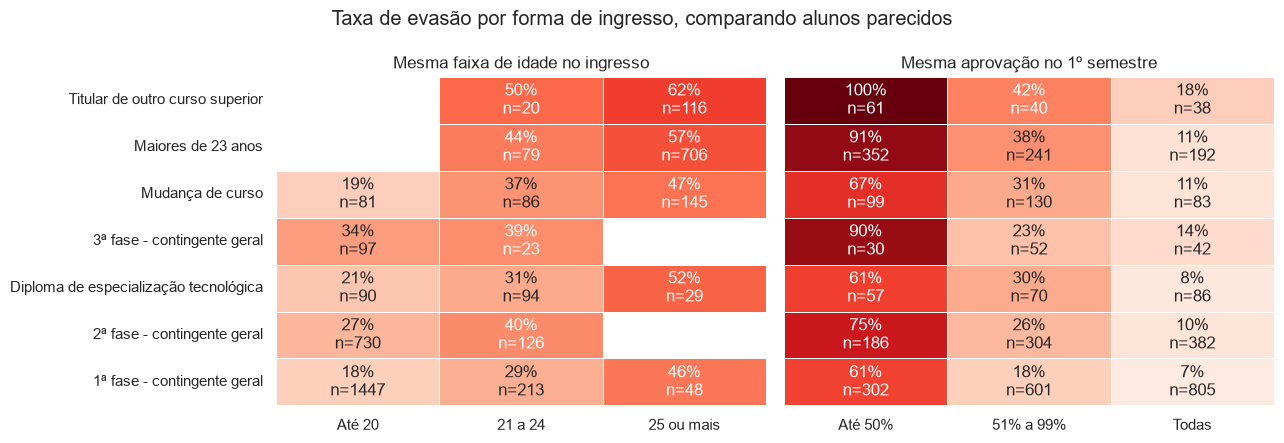

In [10]:
principais = por_forma.index[por_forma["alunos"] >= 100]
ordem_formas = por_forma.loc[principais].sort_values("taxa_evasao", ascending=False).index
base = df[df["nome_forma_ingresso"].isin(principais)].copy()
base["faixa_idade"] = pd.cut(base["idade_ingresso"], bins=[0, 20, 24, 100],
                             labels=["Até 20", "21 a 24", "25 ou mais"])
base["faixa_aprovacao"] = pd.cut(base["taxa_aprovacao_1sem"], bins=[-0.01, 0.5, 0.99, 1.0],
                                 labels=["Até 50%", "51% a 99%", "Todas"])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (coluna, titulo) in zip(eixos, [("faixa_idade", "Mesma faixa de idade no ingresso"),
                                         ("faixa_aprovacao", "Mesma aprovação no 1º semestre")]):
    taxa = pd.crosstab(base["nome_forma_ingresso"], base[coluna], values=base["evadiu"], aggfunc="mean")
    alunos = pd.crosstab(base["nome_forma_ingresso"], base[coluna])
    taxa, alunos = taxa.reindex(ordem_formas), alunos.reindex(ordem_formas).fillna(0)
    taxa = taxa.where(alunos >= 20)
    rotulos = np.where(alunos >= 20, taxa.map(lambda t: f"{t:.0%}") + "\nn=" + alunos.astype(int).astype(str), "")
    sns.heatmap(taxa, annot=rotulos, fmt="", cmap="Reds", vmin=0, vmax=1, cbar=False,
                linewidths=0.5, linecolor="white", ax=ax)
    ax.grid(False)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Taxa de evasão por forma de ingresso, comparando alunos parecidos")
fig.tight_layout()
salvar(fig, "14_forma_ingresso_controles.png")
plt.show()

In [11]:
# Nas três fases do concurso nacional: o curso ser ou não a 1ª opção do aluno explica a diferença?
fases = df[df["forma_ingresso"].isin([1, 17, 18])]
primeira_opcao = (fases["ordem_opcao"].eq(1).map({True: "Era a 1ª opção", False: "Não era a 1ª opção"})
                  .rename("o curso"))
pd.concat({"taxa de evasão": pd.crosstab(fases["nome_forma_ingresso"], primeira_opcao,
                                         values=fases["evadiu"], aggfunc="mean"),
           "alunos": pd.crosstab(fases["nome_forma_ingresso"], primeira_opcao)}, axis=1)

taxa de evasão                            alunos  \
o curso                     Era a 1ª opção Não era a 1ª opção Era a 1ª opção   
nome_forma_ingresso                                                            
1ª fase - contingente geral          0.206              0.197            991   
2ª fase - contingente geral          0.295              0.293            404   
3ª fase - contingente geral          0.237              0.477             59   

                                                
o curso                     Não era a 1ª opção  
nome_forma_ingresso                             
1ª fase - contingente geral                717  
2ª fase - contingente geral                468  
3ª fase - contingente geral                 65

**A forma de ingresso carrega informação própria, que não é só idade nem desempenho:**

- **Mesma idade:** entre alunos de até 20 anos, a evasão vai de 18% (1ª fase) a 27% (2ª fase) e 34% (3ª fase). Entre os de 25 anos ou mais, a 1ª fase fica em 46%, contra 57% dos maiores de 23 anos e 62% dos titulares de outro curso.
- **Mesmo desempenho:** entre quem foi aprovado em **todas** as disciplinas do 1º semestre, a evasão é de 7% na 1ª fase, mas de 11% nos maiores de 23 anos e 18% nos titulares de outro curso. Entre quem aprovou até metade, chega a 91% nos maiores de 23 anos e a 100% (61 de 61) nos titulares de outro curso, contra 61% na 1ª fase.
- **A ordem de opção quase não explica as fases:** na 1ª e na 2ª fase, quem tinha o curso como 1ª opção evade praticamente igual a quem não tinha (21% × 20% e 29% × 29%). Só na 3ª fase aparece diferença (24% × 48%), mas ali são apenas 124 alunos. A diferença entre as fases deve vir de outros fatores, como o perfil de quem fica para as fases seguintes.

**O que isso significa para o projeto:**

1. **Para o modelo:** confirma que vale manter `forma_ingresso` como atributo (one-hot, já agrupando as formas raras). Ela acrescenta sinal mesmo depois de conhecido o desempenho do 1º semestre.
2. **Para a coordenação:** os **maiores de 23 anos** e os **titulares de outro curso** merecem acolhimento específico desde a matrícula, por exemplo com horários flexíveis, apoio para quem trabalha e acompanhamento das mensalidades. Como são grupos que já se conhecem no ingresso, dá para agir antes mesmo do 1º semestre.

⚠️ Como no resto da análise, são **associações, não causas**, e os códigos seguem o sistema de acesso português. Para usar no Brasil seria preciso mapear para as formas locais (SISU e chamadas, vestibular, transferência, portador de diploma).

## 8. Correlação dos atributos com a evasão

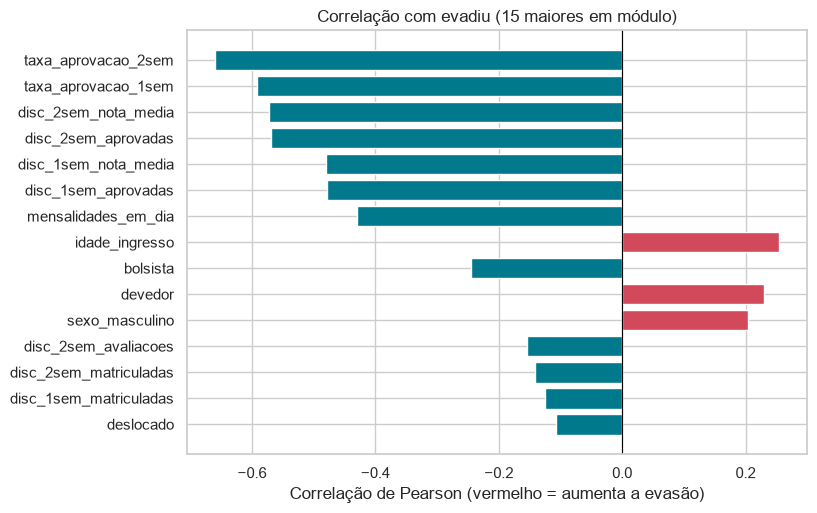

In [12]:
colunas = [c for c in df.select_dtypes("number").columns if c not in CATEGORICAS + ["evadiu"]]
correlacao = df[colunas].corrwith(df["evadiu"]).sort_values(key=abs, ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(correlacao.index[::-1], correlacao.values[::-1],
        color=[CORES["Evadiu"] if v > 0 else CORES["Formado"] for v in correlacao.values[::-1]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlação com evadiu (15 maiores em módulo)")
ax.set_xlabel("Correlação de Pearson (vermelho = aumenta a evasão)")
salvar(fig, "06_correlacao_alvo.png")
plt.show()

As correlações confirmam o que vimos: desempenho acadêmico (aprovação e notas), mensalidades em dia e bolsa **reduzem** a evasão, enquanto idade, ser devedor e sexo masculino **aumentam**. Os indicadores macroeconômicos (desemprego, inflação, PIB) quase não se correlacionam com a evasão.

Os códigos nominais foram deixados de fora desta análise, porque correlação de Pearson não faz sentido para rótulos. Correlação também só mede relação linear e individual. Os modelos de árvore do notebook 02 captam interações que ela não mostra.

## 9. Categorias raras

In [13]:
linhas = []
for coluna in CATEGORICAS:
    contagem = df[coluna].value_counts()
    raras = contagem[contagem < 20]
    linhas.append({"atributo": coluna, "códigos": len(contagem), "códigos com < 20 alunos": len(raras),
                   "alunos nesses códigos": int(raras.sum())})
pd.DataFrame(linhas)

,atributo,códigos,códigos com < 20 alunos,alunos nesses códigos
0,estado_civil,6,2,10
1,forma_ingresso,18,6,32
2,curso,17,1,12
3,escolaridade_anterior,17,9,56
4,nacionalidade,21,19,72
5,escolaridade_mae,29,19,68
6,escolaridade_pai,34,24,82
7,ocupacao_mae,32,20,90
8,ocupacao_pai,46,34,112


Vários atributos nominais têm dezenas de códigos com pouquíssimos alunos. Por exemplo, a nacionalidade tem 21 códigos e 97,5% dos alunos são portugueses. Criar uma coluna para cada código raro geraria atributos quase sempre zero, que favorecem *overfitting*. Por isso o `OneHotEncoder` usa `min_frequency=20`: códigos com menos de 20 alunos no treino são agrupados numa categoria "infrequente". Códigos nunca vistos (num aluno novo, por exemplo) também caem nela, sem erro.

## 10. Resumo dos tratamentos

| Tratamento | Justificativa |
|---|---|
| Renomear colunas para português e remover o TAB do cabeçalho | Legibilidade e evitar erro de leitura |
| Sem imputação nem remoção de linhas | Não há ausentes nem duplicados |
| Outliers mantidos | Valores plausíveis (idade, nota 0 = sem avaliação) |
| Alvo binário: evadiu × não evadiu | Corresponde à decisão real da coordenação |
| One-hot com agrupamento de categorias raras | Códigos nominais não têm ordem, e categorias raras causam overfitting |
| Padronização só na Regressão Logística | É sensível à escala, árvores não são |
| Novo atributo: taxa de aprovação por semestre | Normaliza o desempenho pela carga de disciplinas |
| Três cenários de tempo (matrícula, 1º e 2º semestres) | Cada cenário usa só o que já se sabe naquele momento |
| Todo o pré-processamento dentro de um `Pipeline` | Evita vazamento de dados na validação cruzada |